# Think Bayes — Chapters 04 & 06: Comparing Proportions & Distribution Arithmetic
> *Reference: Paraphrased from Allen Downey's Think Bayes (2nd Edition, Chapters 4 & 6).*

This notebook covers Bayesian comparison of two proportions (A/B testing), direct inequality comparisons, difference distributions $\Delta = B - A$, and distribution arithmetic for sums of independent variables (addends).

In [1]:
import set_paths
import numpy as np
import matplotlib.pyplot as plt
from probability.distributions import GridDistribution1d
from make_data import make_ab_test_data

## 4.1 Comparing Two Proportions (Bayesian A/B Testing)
Suppose we are testing two website designs, clinical treatments, or coin spins:
- **Variant A**: $140$ conversions out of $250$ visitors.
- **Variant B**: $120$ conversions out of $250$ visitors.

In [2]:
ab_data = make_ab_test_data()
data_a = ab_data['variant_a']
data_b = ab_data['variant_b']

prior_a = GridDistribution1d.uniform(0.0, 1.0, 1001, name='p_A')
prior_b = GridDistribution1d.uniform(0.0, 1.0, 1001, name='p_B')

post_a = prior_a.update_binomial(k=data_a['k'], n=data_a['n'])
post_b = prior_b.update_binomial(k=data_b['k'], n=data_b['n'])

print(f"Variant A: Mean={post_a.mean():.4f}, 95% HDI={post_a.hdi(0.95)}")
print(f"Variant B: Mean={post_b.mean():.4f}, 95% HDI={post_b.hdi(0.95)}")

Variant A: Mean=0.5595, 95% HDI=(0.495, 0.617)
Variant B: Mean=0.4802, 95% HDI=(0.41500000000000004, 0.538)


## 4.2 Exact Probability Comparisons & Difference Distribution
`probability` supports direct inequality operators (`>`, `<`, `>=`, `<=`) between distributions, as well as distribution arithmetic (`+`, `-`, `*`).

In [3]:
# Exact probability of superiority P(A > B)
prob_a_beats_b = post_a > post_b
print(f"Probability Variant A > Variant B: {prob_a_beats_b:.2%}")

# Difference distribution Delta = p_A - p_B
diff = post_a - post_b
print(f"Difference Mean:   {diff.mean():.4f}")
print(f"Difference Std:    {diff.std():.4f}")
print(f"Difference 95% HDI:{diff.hdi(0.95)}")
print(f"P(Difference > 0): {(diff > 0.0):.2%}")

Probability Variant A > Variant B: 96.21%
Difference Mean:   0.0793
Difference Std:    0.0443
Difference 95% HDI:(0.00666666666666671, 0.18000000000000005)
P(Difference > 0): 96.40%


## 4.3 Visualizing the Difference Distribution

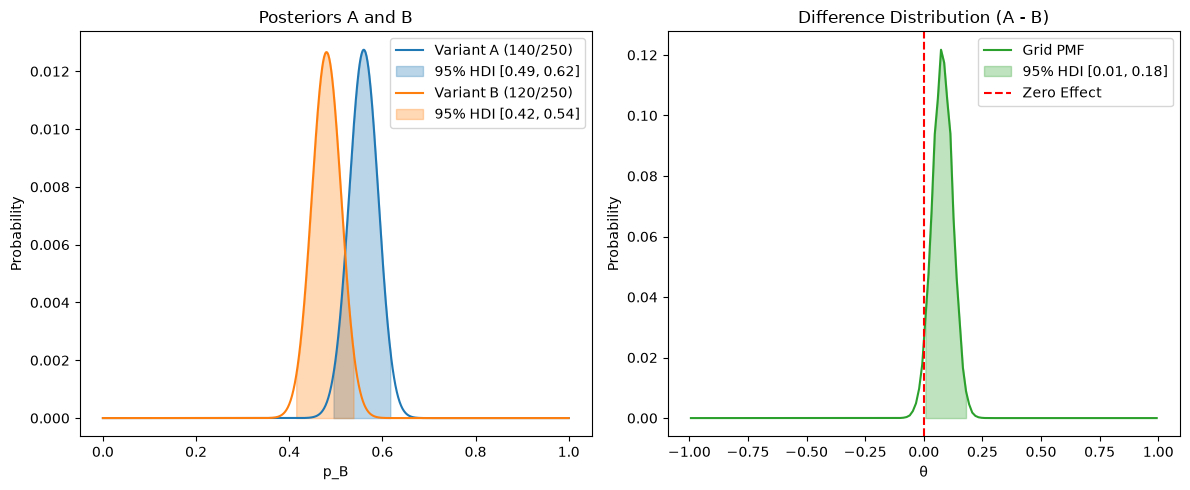

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
post_a.plot(ax=axes[0], color='tab:blue', label='Variant A (140/250)', hdi=0.95)
post_b.plot(ax=axes[0], color='tab:orange', label='Variant B (120/250)', hdi=0.95, title='Posteriors A and B')
axes[0].legend()

diff.plot(ax=axes[1], color='tab:green', hdi=0.95, title='Difference Distribution (A - B)')
axes[1].axvline(0.0, color='red', linestyle='--', label='Zero Effect')
axes[1].legend()
plt.tight_layout()
plt.show()

## 6.1 Distribution Arithmetic & Addends (Chapter 6)
When independent random variables are added, their distribution is the convolution of their probability mass functions.
With `probability`, we can add, multiply, and shift discrete distributions directly.

In [5]:
# 6-sided die
d6 = GridDistribution1d(grid=[1, 2, 3, 4, 5, 6], name='Die')
two_dice = d6 + d6
three_dice = two_dice + d6

print(f"Single Die: E[X] = {d6.mean():.2f}, Var(X) = {d6.var():.2f}")
print(f"Two Dice:   E[X] = {two_dice.mean():.2f}, Var(X) = {two_dice.var():.2f}")
print(f"Three Dice: E[X] = {three_dice.mean():.2f}, Var(X) = {three_dice.var():.2f}")
print(f"P(Two Dice == 7): {(two_dice == 7):.4f} (Theoretical: 6/36 = {6/36:.4f})")

Single Die: E[X] = 3.50, Var(X) = 2.92
Two Dice:   E[X] = 7.03, Var(X) = 5.81
Three Dice: E[X] = 10.55, Var(X) = 8.65
P(Two Dice == 7): 0.0000 (Theoretical: 6/36 = 0.1667)


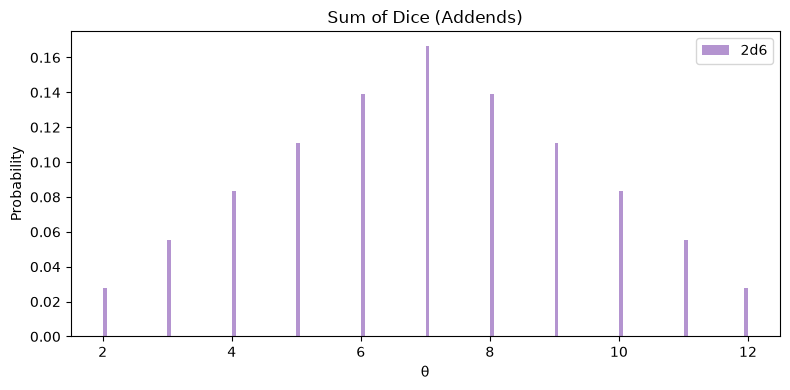

In [6]:
fig, ax = plt.subplots(figsize=(8, 4))
two_dice.plot(ax=ax, kind='bar', color='tab:purple', alpha=0.7, label='2d6', title='Sum of Dice (Addends)')
ax.set_ylabel('Probability')
plt.tight_layout()
plt.show()